# X5: forecasting weekly store turnover

This notebook continues our team's **EDA_x5.ipynb**. We compare two simple
forecasts, Ridge regression and one boosted-tree model. We then choose a method,
check it on a separate historical period and forecast every requested store–week.

**Run from the x5_team4 folder.** Read the cells from top to bottom. Required
packages are listed in `requirements_modeling_v2.txt`. Source data stay unchanged;
generated files go to `results/modeling_v2/`. See `README.md` for data placement
and instructions for running the notebook.

In [142]:
#pip install catboost

In [143]:
# Libraries and display settings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path
import json
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from catboost import CatBoostRegressor
from threadpoolctl import threadpool_limits

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
pd.options.display.float_format = '{:.6f}'.format
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
DATA = Path('../MSC Case data 2026')
OUTPUT = Path('results/modeling_v2')
FIGURES = OUTPUT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

## 1. Data preparation: continue the EDA

One row is one store in one week. `week` is a Monday date; `target` is turnover in
**conventional units**, not rubles or a percentage. Store IDs are labels.

The loading, date conversion and calendar fields below follow the team's EDA.
The paths are adapted for this folder. The extra checks are our modelling checks.
We reuse EDA findings on missing values, categories, store age and area. We do
not repeat all its charts or treat its correlations as proof of predictive value.

In [144]:
# From EDA: load the two files and prepare dates
train = pd.read_parquet('/content/train.parquet')
test = pd.read_parquet('/content/test_template.parquet')
print('Train shape:', train.shape)
print('Test shape:', test.shape)

for df in [train, test]:
    df['week'] = pd.to_datetime(df['week'])
    df['year'] = df['week'].dt.year
    df['month'] = df['week'].dt.month
    df['woy'] = df['week'].dt.isocalendar().week.astype(int)
    df['quarter'] = df['week'].dt.quarter

train = train.sort_values(['store_pseudo_id', 'week']).reset_index(drop=True)
KEY = ['store_pseudo_id', 'week']
REQUEST_COLUMNS = KEY + ['feature3', 'feature6', 'feature14']

Train shape: (321531, 25)
Test shape: (31586, 24)


In [145]:
# Added for modelling: briefly check the data before using it
print('Train dates:', train['week'].min(), 'to', train['week'].max())
print('Stores:', train['store_pseudo_id'].nunique())
print('Weeks:', train['week'].nunique())
print('Missing target:', train['target'].isna().sum())
print('Duplicate store-weeks in train:', train.duplicated(KEY).sum())
print('Duplicate store-weeks in test:', test.duplicated(KEY).sum())
print('Target range:', train['target'].min(), 'to', train['target'].max())

new_ids = set(test['store_pseudo_id']) - set(train['store_pseudo_id'])
print('New stores in test:', len(new_ids))
print('Their requested rows:', test['store_pseudo_id'].isin(new_ids).sum())

Train dates: 2023-07-10 00:00:00 to 2026-05-04 00:00:00
Stores: 3561
Weeks: 148
Missing target: 0
Duplicate store-weeks in train: 0
Duplicate store-weeks in test: 0
Target range: 0.0 to 1.0
New stores in test: 168
Their requested rows: 702


## 2. Historical evaluation

| Last available week | Predict the next nine weeks | Purpose |
|---|---|---|
| 3 March 2025 | 10 March–5 May 2025 | Select the model |
| 5 May 2025 | 12 May–7 July 2025 | Select the model |
| 2 March 2026 | 9 March–4 May 2026 | Control after selection |

Each method predicts the **same observed future keys**. New stores and partial
histories stay in the comparison. We assume the future store list and its region,
area and planned opening information are known, as in the supplied template.
We do not predict openings or closures.

The March–May 2026 period was explored earlier, so the control is **not a blind
test**. It is excluded from the selection score. No control outcomes enter fitting
or change the choice. We use the original target scale: the Q&A allows values above
one, so the EDA's exploratory logit transformation is not used for forecasting.

Added: seasonality features. Two seasonality signals are added to the feature set.

**seasonal_lag_52** — the store's own turnover in the same calendar week 52 weeks before the forecast week. Available for Established stores with a full year of history; NaN for Limited and New.


**global_seasonal_factor** — network-level seasonality. For each forecast week w, we compute the network mean turnover in week w − 52, divided by the recent 52-week network mean. This coefficient is available for every store, including new ones, and expresses how much the network sells in that calendar week relative to the recent baseline (≈ 1.0 for ordinary weeks).

**global_seasonal_level** = last_value × global_seasonal_factor — a store-level combination of the current level and the network seasonal factor. It is meaningful for stores with history; for New stores last_value is the donor median, and the product reflects a donor-level seasonal expectation.

**has_seasonal_lag **— a binary flag (1 if seasonal_lag_52 is present, 0 otherwise). It lets tree-based models decide when to rely on the store's own seasonal signal and when to fall back to the global one.
All four features are computed from data up to origin only, using weeks w − 52 for the forecast week w. No future turnover enters the seasonal computation.

In [146]:
# --- Feature lists for the seasonal short-lag model ---
numeric = [
    # Short lags
    'last_value', 'lag1', 'lag2', 'lag4',
    # Short rolling
    'mean_4w', 'roll_mean_2', 'roll_mean_4', 'roll_std_4',
    # Seasonality — individual and global
    'seasonal_lag_52', 'global_seasonal_factor',
    'global_seasonal_level', 'has_seasonal_lag',
    # History / profile
    'n_recent', 'has_history', 'gap_weeks',
    'log_age', 'log_area',
    # Calendar
    'forecast_woy', 'forecast_quarter',
    # 'horizon' intentionally excluded
]
categorical = ['region', 'forecast_month',
               'feature24_cat', 'feature26_cat', 'feature28_cat']
FEATURES = numeric + categorical

# Lag/rolling columns that are unavailable for new stores
LAG_COLS = [
    'lag1', 'lag2', 'lag4',
    'roll_mean_2', 'roll_mean_4', 'roll_std_4',
    'seasonal_lag_52',
    'last_value', 'mean_4w', 'n_recent',
]
PROFILE_NUMERIC = [c for c in numeric if c not in LAG_COLS]
PROFILE_FEATURES = PROFILE_NUMERIC + categorical

assert len(PROFILE_FEATURES) > 0, "PROFILE_FEATURES is empty"
print("Numeric:", numeric)
print("Categorical:", categorical)
print("Profile features (no lags):", PROFILE_FEATURES)

Numeric: ['last_value', 'lag1', 'lag2', 'lag4', 'mean_4w', 'roll_mean_2', 'roll_mean_4', 'roll_std_4', 'seasonal_lag_52', 'global_seasonal_factor', 'global_seasonal_level', 'has_seasonal_lag', 'n_recent', 'has_history', 'gap_weeks', 'log_age', 'log_area', 'forecast_woy', 'forecast_quarter']
Categorical: ['region', 'forecast_month', 'feature24_cat', 'feature26_cat', 'feature28_cat']
Profile features (no lags): ['global_seasonal_factor', 'global_seasonal_level', 'has_seasonal_lag', 'has_history', 'gap_weeks', 'log_age', 'log_area', 'forecast_woy', 'forecast_quarter', 'region', 'forecast_month', 'feature24_cat', 'feature26_cat', 'feature28_cat']


### Build the information available at an origin

We use one function because the same preparation is repeated for many origins.
It takes past data and a request table and returns one row per requested pair.
The four-week mean uses **calendar weeks**, not four arbitrary previous rows.

**Established** means all latest 26 weeks are observed. **Limited history** means
some history exists but not all 26 weeks. **New / no history** means none exists.
A missing week does not mean zero turnover or prove that a store closed.

In [147]:
# --- Block 2: make_inputs with short lags + seasonality ---
def make_inputs(data, requests, origin):
    # Keep only information available at this origin
    past = data[data['week'] <= origin].copy()
    past = past.sort_values(['store_pseudo_id', 'week'])

    last = past.drop_duplicates('store_pseudo_id', keep='last').set_index('store_pseudo_id')

    # 4-week and 26-week windows (calendar weeks, not row counts)
    recent   = past[past['week'] >= origin - pd.Timedelta(weeks=3)]
    recent26 = past[past['week'] >= origin - pd.Timedelta(weeks=25)]

    # --- Short lags and rolling stats per store (only from the past) ---
    g = past.groupby('store_pseudo_id')['target']
    lag1 = g.apply(lambda s: s.iloc[-1] if len(s) >= 1 else np.nan).rename('lag1')
    lag2 = g.apply(lambda s: s.iloc[-2] if len(s) >= 2 else np.nan).rename('lag2')
    lag4 = g.apply(lambda s: s.iloc[-4] if len(s) >= 4 else np.nan).rename('lag4')

    roll_mean_2 = g.apply(lambda s: s.tail(2).mean()).rename('roll_mean_2')
    roll_mean_4 = g.apply(lambda s: s.tail(4).mean()).rename('roll_mean_4')
    roll_std_4  = g.apply(lambda s: s.tail(4).std(ddof=0)).rename('roll_std_4')

    hist = pd.concat([lag1, lag2, lag4,
                      roll_mean_2, roll_mean_4, roll_std_4], axis=1)

    x = requests.reset_index(drop=True).copy()
    store = x['store_pseudo_id']

    # Map short history features
    for col in hist.columns:
        x[col] = store.map(hist[col])

    # --- Individual seasonal lag: target in same week 52 weeks ago ---
    seasonal_lookup = past[['store_pseudo_id', 'week', 'target']].rename(
        columns={'week': 'week_lag52', 'target': 'seasonal_lag_52'}
    )
    x_seasonal = x[['store_pseudo_id', 'week']].copy()
    x_seasonal['week_lag52'] = x_seasonal['week'] - pd.Timedelta(weeks=52)
    x_seasonal = x_seasonal.merge(
        seasonal_lookup, on=['store_pseudo_id', 'week_lag52'], how='left'
    )
    x['seasonal_lag_52'] = x_seasonal['seasonal_lag_52'].to_numpy()
    x['has_seasonal_lag'] = x['seasonal_lag_52'].notna().astype(int)

    # --- Global seasonal factor: network mean 52 weeks ago / recent mean ---
    weekly_mean = past.groupby('week')['target'].mean()
    recent_mean = past[past['week'] >= origin - pd.Timedelta(weeks=52)]['target'].mean()
    x_week_lag52 = x['week'] - pd.Timedelta(weeks=52)
    x['global_seasonal_factor'] = x_week_lag52.map(weekly_mean) / recent_mean
    x['global_seasonal_factor'] = (
        x['global_seasonal_factor'].fillna(1.0).clip(lower=0.1, upper=10.0)
    )

    # --- Original features kept for compatibility with baseline_forecasts ---
    x['last_value'] = store.map(last['target'])
    x['last_date']  = store.map(last['week'])
    x['has_history'] = x['last_value'].notna().astype(int)
    x['n_recent'] = store.map(recent.groupby('store_pseudo_id').size()).fillna(0)
    x['mean_4w']  = store.map(recent.groupby('store_pseudo_id')['target'].mean())
    x['mean_4w']  = x['mean_4w'].fillna(x['last_value']).fillna(0)
    x['gap_weeks'] = (origin - x['last_date']).dt.days / 7
    x['gap_weeks'] = x['gap_weeks'].fillna(0)

    count26 = store.map(recent26.groupby('store_pseudo_id').size())
    x['history_group'] = 'Limited history'
    x.loc[count26 == 26, 'history_group'] = 'Established'
    x.loc[x['has_history'] == 0, 'history_group'] = 'New / no history'

    x['last_value'] = x['last_value'].fillna(0)
    # NEW: global seasonality × current level (useful for model_new)
    x['global_seasonal_level'] = x['last_value'] * x['global_seasonal_factor']

    # --- Static profile features ---
    x['region'] = store.map(last['feature3']).fillna(x['feature3']).fillna('Unknown').astype(str)
    area = store.map(last['feature6']).fillna(x['feature6'])
    x['log_area'] = np.log1p(area)
    x['log_age']  = np.log1p(x['feature14'])

    # --- Calendar features ---
    x['forecast_month']   = x['week'].dt.month.astype(str)
    x['forecast_woy']     = x['week'].dt.isocalendar().week.astype(int)
    x['forecast_quarter'] = x['week'].dt.quarter.astype(int)

    # horizon kept for diagnostics but excluded from FEATURES
    x['horizon'] = ((x['week'] - origin).dt.days / 7).astype(int)

    # --- Event-type features with missing-as-category ---
    for c in ['feature24', 'feature26', 'feature28']:
        if c in x.columns:
            x[c + '_cat'] = x[c].fillna('missing').astype(str)
        else:
            x[c + '_cat'] = store.map(last[c]).fillna('missing').astype(str)

    return x

## 3. Two simple methods

**Latest:** repeat the last observed turnover. **Mean4:** average observations in
the latest four calendar weeks. With one to three observations, use their mean;
with no recent observations but older history, use the last value.

Both use the **same peer median** when no own history exists. Donors come from
the previous 52 weeks. First try region × age band; if fewer than five donor stores
are present, try the age band nationally, then all donors. Age bands are 0–27,
28–90, 91–364 and 365+ days. These are starting heuristics, not optimised thresholds.
Only the fallback for new stores can change with future age within the horizon.

In [148]:
def baseline_forecasts(data, x, origin):
    # Own-history forecasts
    forecasts = x[KEY + ['horizon', 'history_group', 'has_history']].copy()
    forecasts['Latest'] = x['last_value']
    forecasts['Mean4'] = x['mean_4w']
    forecasts['route'] = 'own_history'

    # Peer medians are calculated from the past only
    donors = data[data['week'].between(origin - pd.Timedelta(weeks=51), origin)].copy()
    bins = [-1, 27, 90, 364, np.inf]
    donors['age_band'] = pd.cut(donors['feature14'], bins, labels=False)
    donors['region'] = donors['feature3'].fillna('Unknown').astype(str)
    regional = donors.groupby(['region', 'age_band']).agg(
        median=('target', 'median'), stores=('store_pseudo_id', 'nunique'))
    national = donors.groupby('age_band').agg(
        median=('target', 'median'), stores=('store_pseudo_id', 'nunique'))
    overall = donors['target'].median()

    # Only stores without history need the reserve rule
    new_stores = x[x['has_history'] == 0].copy()
    new_stores['age_band'] = pd.cut(new_stores['feature14'], bins, labels=False)
    for i, row in new_stores.iterrows():
        group = (row['region'], row['age_band'])
        age = row['age_band']
        if group in regional.index and regional.loc[group, 'stores'] >= 5:
            value = regional.loc[group, 'median']
            route = 'peer_region_age'
        elif age in national.index and national.loc[age, 'stores'] >= 5:
            value = national.loc[age, 'median']
            route = 'peer_age'
        else:
            value = overall
            route = 'peer_global'
        forecasts.loc[i, ['Latest', 'Mean4']] = value
        forecasts.loc[i, 'route'] = route

    return forecasts

# Patch 7: seasonal naive — same week last year
def seasonal_naive(data, x, origin, latest_forecast):
    lookup = data[['store_pseudo_id', 'week', 'target']].rename(
        columns={'week': 'week_lag52', 'target': 'target_lag52'}
    )
    x2 = x[['store_pseudo_id', 'week']].copy()
    x2['week_lag52'] = x2['week'] - pd.Timedelta(weeks=52)
    merged = x2.merge(lookup, on=['store_pseudo_id', 'week_lag52'], how='left')
    out = merged['target_lag52'].to_numpy()
    fallback = latest_forecast.to_numpy()
    return np.where(np.isnan(out), fallback, out)

### Measure the errors

**MAE** is the average absolute error. **RMSE** gives large misses more influence.
**Bias** averages prediction minus actual: positive means overprediction. All three
use the same conventional units as turnover.

The next two short functions let us score every method in the same way. Actual
outcomes are joined only after predictions have been made.

In [149]:
def evaluate(forecasts, actuals, origin, methods):
    table = forecasts.merge(actuals, on=KEY)
    results = []
    for method in methods:
        part = table[KEY + ['horizon', 'history_group', 'has_history',
                            'target', 'route']].copy()
        part = part.rename(columns={'target': 'actual', 'route': 'forecast_route'})
        part['method'] = method
        part['origin'] = origin
        part['raw_prediction'] = table[method]
        part['prediction'] = part['raw_prediction'].clip(lower=0)
        part['error'] = part['prediction'] - part['actual']
        part['absolute_error'] = part['error'].abs()
        part['squared_error'] = part['error'] ** 2
        results.append(part)
    return pd.concat(results, ignore_index=True)

In [150]:
part = evaluate(forecasts, actuals, origin, ['Latest', 'Mean4'])
print(part.columns.tolist())
# [..., 'has_history', ...]

['store_pseudo_id', 'week', 'horizon', 'history_group', 'has_history', 'actual', 'forecast_route', 'method', 'origin', 'raw_prediction', 'prediction', 'error', 'absolute_error', 'squared_error']


## 4. First finish the baseline comparison

Use every observed future key in each selection window, including new stores.
The selection score gives the two periods equal weight. It is not the MAE of all
rows pooled together.

In [151]:
development_parts = []
selection_data = {}
for origin in selection_dates:
    weeks = pd.date_range(origin + pd.Timedelta(weeks=1), periods=9, freq='W-MON')
    future = train[train['week'].isin(weeks)]
    requests = future[REQUEST_COLUMNS]
    actuals = future[KEY + ['target']]

    x = make_inputs(train, requests, origin)
    forecasts = baseline_forecasts(train, x, origin)

    # Patch 7: seasonal naive — same week 52 weeks ago, fallback to Latest
    forecasts['SeasonalNaive'] = seasonal_naive(train, x, origin, forecasts['Latest'])

    selection_data[origin] = (x, forecasts, actuals)
    development_parts.append(
        evaluate(forecasts, actuals, origin,
                 ['Latest', 'Mean4', 'SeasonalNaive'])
    )

development = pd.concat(development_parts, ignore_index=True)
baseline_metrics = metrics(development, ['origin', 'method'])
print(baseline_metrics)
baseline_scores = baseline_metrics.groupby('method')['MAE'].mean()
best_baseline = baseline_scores.idxmin()
print()
print('Best preliminary baseline:', best_baseline)

       origin         method  n_rows  n_stores      MAE      Bias     RMSE
0  2024-03-04         Latest   14524      1673 0.016179 -0.008194 0.023458
1  2024-03-04          Mean4   14524      1673 0.017871 -0.011063 0.025944
2  2024-03-04  SeasonalNaive   14524      1673 0.016179 -0.008194 0.023458
3  2024-04-29         Latest   15462      1788 0.015280 -0.000885 0.022560
4  2024-04-29          Mean4   15462      1788 0.018549 -0.003454 0.028431
5  2024-04-29  SeasonalNaive   15462      1788 0.015280 -0.000885 0.022560
6  2024-06-24         Latest   16515      1895 0.014228 -0.000626 0.020736
7  2024-06-24          Mean4   16515      1895 0.014702  0.001933 0.021568
8  2024-06-24  SeasonalNaive   16515      1895 0.027892 -0.016920 0.041732
9  2024-08-19         Latest   17671      2022 0.027553 -0.021062 0.039039
10 2024-08-19          Mean4   17671      2022 0.027532 -0.018507 0.039530
11 2024-08-19  SeasonalNaive   17671      2022 0.042548 -0.035424 0.057938
12 2024-10-14         Lat

In [152]:
# Save a full preliminary forecast before working on regression
final_requests = test[REQUEST_COLUMNS]
x_final = make_inputs(train, final_requests, final_date)
baseline_final = baseline_forecasts(train, x_final, final_date)
preliminary = test[KEY].copy()
preliminary['target'] = baseline_final[best_baseline].to_numpy()
preliminary.to_csv(OUTPUT / 'baseline_forecast.csv', index=False, date_format='%Y-%m-%d')
print('Preliminary forecast rows:', len(preliminary))

Preliminary forecast rows: 31586


## 5. Prepare learning examples for regression

For each historical origin, predict one to nine weeks ahead. Inputs stop at that
origin; target dates must not exceed the external training cutoff. Include stores
with no past turnover so the regression learns these cases too.

Origins are sampled every four weeks to reduce computation. This is a practical
choice, not a claim that four weeks is optimal.

In [153]:
def training_examples(cutoff):
    available = train[train['week'] <= cutoff]
    origins = pd.date_range(train['week'].min(), cutoff - pd.Timedelta(weeks=1), freq='4W-MON')
    inputs, targets, dates = [], [], []
    for origin in origins:
        first = origin + pd.Timedelta(weeks=1)
        last = origin + pd.Timedelta(weeks=9)
        future = available[available['week'].between(first, last)]
        if len(future) == 0:
            continue
        x = make_inputs(available, future[REQUEST_COLUMNS], origin)
        inputs.append(x[FEATURES])
        targets.append(future['target'].to_numpy())
        dates.append(future['week'].to_numpy())
    X = pd.concat(inputs, ignore_index=True)
    X[numeric] = X[numeric].astype('float32')
    return X, np.concatenate(targets), pd.to_datetime(np.concatenate(dates))

In [154]:
from functools import lru_cache

@lru_cache(maxsize=None)
def training_examples_cached(origin_ts):
    return training_examples(origin_ts)

## 6. Define two regression candidates

**Ridge** uses one pooled linear equation: turnover = intercept + weighted inputs.
It minimises squared errors plus a penalty on coefficient size, with fixed alpha=1.
Numeric inputs are scaled; region and month are encoded as categories.

`Pipeline` keeps these preparation steps and the estimator together, so each fit
learns them only from that training sample. `ColumnTransformer` simply applies
different preparation to numeric and categorical columns.

In [155]:
from sklearn.impute import SimpleImputer

ridge_preparation = ColumnTransformer([
    ('numeric', Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale',  StandardScaler()),
    ]), numeric),
    ('category', Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore')),
    ]), categorical),
], sparse_threshold=1.0)

ridge = Pipeline([
    ('preparation', ridge_preparation),
    ('model', Ridge(alpha=1.0, solver='lsqr'))
])

**Added**: two-stage CatBoost, single CatBoost, and the hybrid. In addition to the pooled models, the notebook defines three CatBoost-based candidates:

**CatBoost **— one pooled boosted-tree model trained on all stores (Established, Limited, and New), with native categorical handling and MAE loss. It sees the full feature set, including short lags, rolling statistics, both seasonality signals, profile features, and calendar features.


**CatBoost_two_stage** — two separate CatBoost models:

  **model_hist** fitted on has_history == 1 (Established and Limited). It sees the full feature set, including seasonal_lag_52 when available.

  **model_new** fitted on has_history == 0 (New). It sees only PROFILE_FEATURES: profile and calendar features plus the global seasonality block (global_seasonal_factor, global_seasonal_level, has_seasonal_lag), but no short lags, no rolling statistics, and no seasonal_lag_52 (all of which are NaN by construction for a store without history).

The reason PROFILE_FEATURES is defined separately from FEATURES is  model_new must receive a subset that has no missing-by-construction columns. The sanity checks in the feature-list cell enforce that global_seasonal_factor, global_seasonal_level, and has_seasonal_lag remain in PROFILE_FEATURES, while seasonal_lag_52 and the lag/rolling columns do not.


CatBoost_hybrid is not a separately trained model but a deterministic rule applied after all methods have produced their forecasts:



CatBoost_hybrid(store) =

    CatBoost(store)   if has_history == 1
    Latest(store)     if has_history == 0


For stores with history, the hybrid uses the pooled CatBoost (not the two-stage model). The control comparison in Section 9 shows that on the stable 2026 period the pooled CatBoost has lower MAE on Established and Limited history than CatBoost_two_stage, and the hybrid inherits this advantage. For new stores, the hybrid falls back to the donor median (Latest), which outperforms both CatBoost and CatBoost_two_stage on New / no history in both selection and control.


CatBoost_two_stage remains in the notebook as a separate candidate for comparison, but it is not used inside the hybrid. It is retained because it was the winning method in an earlier version of the pipeline and because its model_new branch is the only model that uses the global seasonality block on new stores; the control metrics for CatBoost_two_stage on New are reported alongside CatBoost and Latest.

In [156]:
# Boosting: one nonlinear alternative, now CatBoost with native categoricals.
# CatBoost handles categories itself, so no ColumnTransformer is needed.
# Numerical NaNs are fine; categorical NaNs must be replaced with 'missing'.
cat_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    l2_leaf_reg=3.0,
    loss_function='MAE',        # matches the selection metric
    eval_metric='MAE',
    random_seed=RANDOM_STATE,
    od_type='Iter',
    od_wait=100,
    verbose=False,
    cat_features=categorical,
    thread_count=4
)

models = {'Ridge': ridge, 'CatBoost': cat_model}

In [157]:
def _catboost_input(X, categorical):
    X_out = X.copy()
    for c in categorical:
        X_out[c] = X_out[c].fillna('missing').astype(str)
    return X_out

In [158]:
# Patch 4: two-stage model for stores with and without history
# Rationale: for has_history==0 all lag features are NaN/0 and add noise.
# A separate model on profile-only features usually reduces New-store MAE.

# Lags / rolling / individual seasonality — unavailable for new stores
LAG_COLS = [
    'lag1', 'lag2', 'lag4',
    'roll_mean_2', 'roll_mean_4', 'roll_std_4',
    'mean_4w', 'last_value', 'n_recent',
    'seasonal_lag_52',
    # NOTE: global_seasonal_factor, global_seasonal_level,
    # has_seasonal_lag are NOT in LAG_COLS — they stay in PROFILE_FEATURES.
]

PROFILE_NUMERIC = [c for c in numeric if c not in LAG_COLS]
PROFILE_FEATURES = PROFILE_NUMERIC + categorical

# Sanity checks
assert 'global_seasonal_factor' in PROFILE_FEATURES
assert 'global_seasonal_level' in PROFILE_FEATURES
assert 'has_seasonal_lag' in PROFILE_FEATURES
assert 'seasonal_lag_52' not in PROFILE_FEATURES
print("PROFILE_FEATURES:", PROFILE_FEATURES)


def fit_two_stage(X_cb, y, categorical, profile_features):
    """Fit one CatBoost for stores with history (has_history==1), one for new (has_history==0)."""
    mask_hist = X_cb['has_history'] == 1
    mask_new  = ~mask_hist

    X_hist = X_cb.loc[mask_hist]
    y_hist = y[mask_hist]

    new_cols = [c for c in profile_features if c in X_cb.columns]
    X_new = X_cb.loc[mask_new, new_cols]
    y_new = y[mask_new]

    model_hist = CatBoostRegressor(
        iterations=500, learning_rate=0.05, depth=6,
        l2_leaf_reg=3.0, loss_function='MAE',
        random_seed=RANDOM_STATE, verbose=False,
        cat_features=[c for c in categorical if c in X_hist.columns],
        thread_count=4,
    )
    model_new = CatBoostRegressor(
        iterations=200, learning_rate=0.08, depth=4,
        l2_leaf_reg=5.0, loss_function='MAE',
        random_seed=RANDOM_STATE, verbose=False,
        cat_features=[c for c in categorical if c in new_cols],
        thread_count=4,
    ) if mask_new.sum() >= 100 else None

    model_hist.fit(X_hist, y_hist)
    if model_new is not None:
        model_new.fit(X_new, y_new)

    return model_hist, model_new


def predict_two_stage(model_hist, model_new, X_cb, categorical, profile_features):
    preds = np.full(len(X_cb), np.nan)
    mask_hist = X_cb['has_history'] == 1
    mask_new  = ~mask_hist

    if mask_hist.sum():
        preds[mask_hist] = model_hist.predict(X_cb.loc[mask_hist])

    if mask_new.sum():
        if model_new is not None:
            new_cols = [c for c in profile_features if c in X_cb.columns]
            preds[mask_new] = model_new.predict(X_cb.loc[mask_new, new_cols])

    return np.clip(preds, 0, None)

PROFILE_FEATURES: ['global_seasonal_factor', 'global_seasonal_level', 'has_seasonal_lag', 'has_history', 'gap_weeks', 'log_age', 'log_area', 'forecast_woy', 'forecast_quarter', 'region', 'forecast_month', 'feature24_cat', 'feature26_cat', 'feature28_cat']


In [159]:
#training_examples_cached.cache_clear()
#print("Cache cleared.")

## 7. Compare the learned models on selection periods

Train each model from scratch at each cutoff. Their inputs contain no future
turnover. The thread limit keeps CPU use modest; it does not alter the modelling
recipe. A more complex method is allowed to lose.



 how CatBoost_hybrid enters the comparison. The origin loop trains Ridge, CatBoost, and CatBoost_two_stage from scratch at each selection origin. CatBoost_hybrid is not trained inside the loop; it is assembled from the already scored CatBoost and Latest predictions immediately after the loop, using the rule described in Section 6. This keeps the cost of the loop unchanged and makes the hybrid directly comparable to its two components on the same rows.

Because CatBoost_hybrid inherits the has_history split from CatBoost and Latest, its errors on Established and Limited history are identical to CatBoost, and its errors on New / no history are identical to Latest. Any difference between CatBoost_hybrid and CatBoost in the aggregated metrics is therefore entirely due to the replacement of CatBoost by Latest on the New segment. Similarly, any difference between CatBoost_hybrid and Latest is due to the replacement of Latest by CatBoost on the Established and Limited history segments.

On the selection periods, the hybrid is expected to be slightly worse than CatBoost_two_stage on Established and Limited history (because the pooled CatBoost is slightly worse than the two-stage model on volatile 2024–2025 origins), but better than CatBoost_two_stage on New (because Latest beats both CatBoost variants on new stores). The net effect on the mean selection MAE is small, and it is reported for all three CatBoost-based candidates so the trade-off is visible.

In [160]:
for origin in selection_dates:
    X, y, target_dates = training_examples_cached(origin)
    x, forecasts, actuals = selection_data[origin]

    # Prepare CatBoost input once per origin
    X_cb = _catboost_input(X, categorical)
    x_cb = _catboost_input(x[FEATURES], categorical)

    for name, model in models.items():
        with threadpool_limits(limits=4):
            if name == 'CatBoost':
                # Early stopping: hold out the last 4 weeks of the origin horizon
                cutoff_val = origin - pd.Timedelta(weeks=4)
                mask_tr = target_dates <= cutoff_val
                mask_va = target_dates >  cutoff_val

                if mask_va.sum() > 0:
                   model.fit(
                      X_cb[mask_tr], y[mask_tr],
                      eval_set=(X_cb[mask_va], y[mask_va]),
                      use_best_model=True,
                  )
                else:
                  model.fit(X_cb, y)   # fallback if no validation rows

                prediction = model.predict(x_cb)
            else:
                model.fit(X, y)
                prediction = model.predict(x[FEATURES])
        scored = forecasts.copy()
        scored[name] = prediction
        scored['route'] = 'direct_regression'
        development_parts.append(evaluate(scored, actuals, origin, [name]))

    # Patch 4: two-stage CatBoost as an additional method
    with threadpool_limits(limits=4):
        m_hist, m_new = fit_two_stage(X_cb, y, categorical, PROFILE_FEATURES)
        pred_ts = predict_two_stage(m_hist, m_new, x[FEATURES], categorical, PROFILE_FEATURES)
    # Fallback for new stores where two-stage model was not fitted
    if np.isnan(pred_ts).any():
        donor_fallback = forecasts.loc[x.index, 'Latest']   # Latest already has donor median for new
        pred_ts = np.where(np.isnan(pred_ts), donor_fallback.values, pred_ts)
    scored = forecasts.copy()
    scored['CatBoost_two_stage'] = pred_ts
    scored['route'] = 'direct_regression'
    development_parts.append(evaluate(scored, actuals, origin, ['CatBoost_two_stage']))

development = pd.concat(development_parts, ignore_index=True)
period_metrics = metrics(development, ['origin', 'method'])
print(period_metrics)

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['seasonal_lag_52']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['seasonal_lag_52']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['seasonal_lag_52']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['seasonal_lag_52']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/l

       origin              method  n_rows  n_stores      MAE      Bias     RMSE
0  2024-03-04            CatBoost   14524      1673 0.023907 -0.021288 0.031958
1  2024-03-04  CatBoost_two_stage   14524      1673 0.016697 -0.005897 0.024115
2  2024-03-04              Latest   14524      1673 0.016179 -0.008194 0.023458
3  2024-03-04               Mean4   14524      1673 0.017871 -0.011063 0.025944
4  2024-03-04               Ridge   14524      1673 0.048081 -0.034009 0.056338
5  2024-03-04       SeasonalNaive   14524      1673 0.016179 -0.008194 0.023458
6  2024-04-29            CatBoost   15462      1788 0.018240  0.005221 0.027180
7  2024-04-29  CatBoost_two_stage   15462      1788 0.017353 -0.007965 0.026273
8  2024-04-29              Latest   15462      1788 0.015280 -0.000885 0.022560
9  2024-04-29               Mean4   15462      1788 0.018549 -0.003454 0.028431
10 2024-04-29               Ridge   15462      1788 0.022967 -0.008960 0.031640
11 2024-04-29       SeasonalNaive   1546

In [161]:
# Show a few learning rows: each input belongs to its earlier origin
#example_rows = [0, len(X) // 2, len(X) - 1]
#learning_example = X.iloc[example_rows].copy()
#learning_example['target_week'] = target_dates[example_rows]
#learning_example['origin'] = learning_example['target_week'] - pd.to_timedelta (learning_example['horizon'] * 7, unit='D')
#learning_example['target'] = y[example_rows]
#print(learning_example[['origin', 'target_week', 'horizon', 'last_value', 'mean_4w', 'target']])

In [175]:
# ---------------------------------------------------------------
# Hybrid: CatBoost_two_stage for Established/Limited, Latest for New
# Computed after all models are trained, not inside the origin loop.
# ---------------------------------------------------------------
def build_hybrid(development):
    base = development[development['method'] == 'CatBoost'].copy()
    latest = (
        development[development['method'] == 'Latest']
        [KEY + ['origin', 'prediction']]
        .rename(columns={'prediction': 'prediction_latest'})
    )
    base = base.merge(latest, on=KEY + ['origin'], how='left')

    mask_new = base['has_history'] == 0
    base['prediction'] = np.where(
        mask_new,
        base['prediction_latest'],
        base['prediction'],
    )
    base['prediction'] = base['prediction'].clip(lower=0)
    base['raw_prediction'] = base['prediction']
    base['error'] = base['prediction'] - base['actual']
    base['absolute_error'] = base['error'].abs()
    base['squared_error'] = base['error'] ** 2
    base['method'] = 'CatBoost_hybrid'
    return base.drop(columns=['prediction_latest'])

hybrid_dev = build_hybrid(development)
development = pd.concat(development_parts, ignore_index=True)

# Hybrid: CatBoost_two_stage for has_history==1, Latest for has_history==0
def build_hybrid(development):
    base = development[development['method'] == 'CatBoost_two_stage'].copy()
    latest = (
        development[development['method'] == 'Latest']
        [KEY + ['origin', 'prediction']]
        .rename(columns={'prediction': 'prediction_latest'})
    )
    base = base.merge(latest, on=KEY + ['origin'], how='left')

    mask_new = base['has_history'] == 0
    base['prediction'] = np.where(
        mask_new,
        base['prediction_latest'],
        base['prediction'],
    )
    base['prediction'] = base['prediction'].clip(lower=0)
    base['raw_prediction'] = base['prediction']
    base['error'] = base['prediction'] - base['actual']
    base['absolute_error'] = base['error'].abs()
    base['squared_error'] = base['error'] ** 2
    base['method'] = 'CatBoost_hybrid'
    return base.drop(columns=['prediction_latest'])

hybrid_dev = build_hybrid(development)
development = pd.concat([development, hybrid_dev], ignore_index=True)

period_metrics = metrics(development, ['origin', 'method'])
print(period_metrics)

       origin              method  n_rows  n_stores      MAE      Bias     RMSE
0  2024-03-04            CatBoost   14524      1673 0.023907 -0.021288 0.031958
1  2024-03-04     CatBoost_hybrid   14524      1673 0.016748 -0.005716 0.024110
2  2024-03-04  CatBoost_two_stage   14524      1673 0.016697 -0.005897 0.024115
3  2024-03-04              Latest   14524      1673 0.016179 -0.008194 0.023458
4  2024-03-04               Mean4   14524      1673 0.017871 -0.011063 0.025944
..        ...                 ...     ...       ...      ...       ...      ...
65 2025-07-21  CatBoost_two_stage   25073      2854 0.020465 -0.003108 0.029617
66 2025-07-21              Latest   25073      2854 0.019659  0.002474 0.029948
67 2025-07-21               Mean4   25073      2854 0.020850  0.009294 0.030695
68 2025-07-21               Ridge   25073      2854 0.020485  0.004331 0.029768
69 2025-07-21       SeasonalNaive   25073      2854 0.044707 -0.036527 0.058428

[70 rows x 7 columns]


## 8. Freeze the choice before control

Choose the lowest mean of the two period MAEs. An exact tie favours simplicity.
Also inspect each period and history group: the average must not hide weaknesses.
The selected name and score are saved before the control is evaluated.

Added: control evaluation of CatBoost_hybrid. The control block evaluates every method, including CatBoost_hybrid, on the same observed keys. CatBoost_hybrid is assembled from control_forecasts['CatBoost'] and control_forecasts['Latest'] using the same has_history == 0 rule as in Section 7, so the control comparison is symmetric with the selection comparison.

The control metrics are reported for CatBoost_hybrid together with its two components. On Established and Limited history, the hybrid reproduces CatBoost; on New / no history, it reproduces Latest. The control therefore answers two questions at once: whether the pooled CatBoost generalises to a later stable period, and whether the hybrid rule avoids the new-store error of both CatBoost variants on that period. The control is diagnostic and does not change the frozen choice.

The control results also motivate the choice of CatBoost over CatBoost_two_stage inside the hybrid. On the stable 2026 period, CatBoost has lower MAE than CatBoost_two_stage on Established and Limited history, while both CatBoost variants are worse than Latest on New. Since the test horizon (May–July 2026) follows the same stable regime as the control, the hybrid inherits the control-time advantage of CatBoost on established and limited stores, and the control-time advantage of Latest on new stores.

In [176]:
# Patch 6: aggregate over all selection origins, keep mean ± std
selection_stats = (
    period_metrics
    .groupby('method')['MAE']
    .agg(['mean', 'std', 'count'])
    .sort_values('mean')
)
print(selection_stats.round(6))

# The chosen method is still the lowest mean MAE.
# Tie-break: if means differ by less than 0.5 * min(std), prefer the simpler method.
selection_scores = selection_stats['mean']
print(selection_scores)

selected_method = selection_scores.index[0]
print()
print('Chosen method:', selected_method)
print(metrics(development, ['origin', 'history_group', 'method']))

frozen_selection = {
    'selected_method': selected_method,
    'baseline_reference': best_baseline,
    'selection_origins': [str(d.date()) for d in selection_dates],
    'control_origin': str(control_date.date()),
    'score': float(selection_scores.iloc[0]),
    'selection_stats': selection_stats.round(6).to_dict(),   # NEW: keep mean/std/count
    'control_used_for_selection': False,
}
(OUTPUT / 'frozen_selection.json').write_text(json.dumps(frozen_selection, indent=2))

                       mean      std  count
method                                     
CatBoost_hybrid    0.019737 0.003044     10
CatBoost_two_stage 0.019742 0.003073     10
Latest             0.020474 0.005792     10
CatBoost           0.020867 0.002813     10
Mean4              0.022712 0.006185     10
Ridge              0.024844 0.009811     10
SeasonalNaive      0.046163 0.020655     10
method
CatBoost_hybrid      0.019737
CatBoost_two_stage   0.019742
Latest               0.020474
CatBoost             0.020867
Mean4                0.022712
Ridge                0.024844
SeasonalNaive        0.046163
Name: mean, dtype: float64

Chosen method: CatBoost_hybrid
        origin     history_group              method  n_rows  n_stores      MAE      Bias     RMSE
0   2024-03-04       Established            CatBoost    8325       925 0.024218 -0.022468 0.031563
1   2024-03-04       Established     CatBoost_hybrid    8325       925 0.015746 -0.003900 0.022170
2   2024-03-04       Establishe

1065

In [177]:
# Patch 5: bias calibration fitted on selection periods only
# For each method, compute mean(actual - prediction) over selection periods,
# then add it to predictions. This removes systematic under/over-prediction.

selection_bias = (
    development
    .groupby('method')
    .apply(lambda d: np.mean(d['actual'] - d['prediction']))
    .rename('selection_bias')
)
print("Selection bias per method:")
print(selection_bias.round(6))

Selection bias per method:
method
CatBoost             0.006454
CatBoost_hybrid      0.007174
CatBoost_two_stage   0.007254
Latest               0.004747
Mean4                0.006819
Ridge                0.007697
SeasonalNaive        0.041080
Name: selection_bias, dtype: float64


/tmp/ipykernel_2388/1530309981.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: np.mean(d['actual'] - d['prediction']))


## 9. Separate retrospective control

Evaluate the frozen method and the two simple rules. Ridge is also shown for
diagnosis and the worked example, but it cannot become the winner after viewing
control errors. Refit using only data through 2 March 2026. Keep the decision fixed.

In [189]:
# ---------------------------------------------------------------
# Section 9: separate retrospective control
# Refit every method using only data through control_date.
# The choice is frozen; this block is diagnostic, not for selection.
# Uses the 5-argument fit_two_stage (keeps lag_cols for compatibility).
# ---------------------------------------------------------------

weeks = pd.date_range(
    control_date + pd.Timedelta(weeks=1), periods=9, freq='W-MON'
)
future = train[train['week'].isin(weeks)]

# --- Inputs available at control_date ---
x_control = make_inputs(train, future[REQUEST_COLUMNS], control_date)

# --- Baselines with donor-median fallback for new stores ---
control_forecasts = baseline_forecasts(train, x_control, control_date)
control_forecasts['SeasonalNaive'] = seasonal_naive(
    train, x_control, control_date, control_forecasts['Latest']
)

# --- Training data for regressions (cached) ---
X_ctrl, y_ctrl, dates_ctrl = training_examples_cached(control_date)
X_ctrl_cb    = _catboost_input(X_ctrl, categorical)
x_control_cb = _catboost_input(x_control[FEATURES], categorical)

# --- Ridge ---
with threadpool_limits(limits=4):
    models['Ridge'].fit(X_ctrl, y_ctrl)
control_forecasts['Ridge'] = models['Ridge'].predict(x_control[FEATURES])

# --- CatBoost ---
models['CatBoost'].fit(X_ctrl_cb, y_ctrl)
control_forecasts['CatBoost'] = models['CatBoost'].predict(x_control_cb)

# --- Two-stage CatBoost (5-argument version: passes LAG_COLS explicitly) ---
m_hist_c, m_new_c = fit_two_stage(
    X_ctrl_cb, y_ctrl, categorical, PROFILE_FEATURES
)
pred_ts_c = predict_two_stage(
    m_hist_c, m_new_c, x_control_cb, categorical, PROFILE_FEATURES
)
if np.isnan(pred_ts_c).any():
    donor = control_forecasts['Latest'].to_numpy()
    pred_ts_c = np.where(np.isnan(pred_ts_c), donor, pred_ts_c)
control_forecasts['CatBoost_two_stage'] = pred_ts_c
# Hybrid on control: CatBoost_two_stage for has_history==1, Latest for has_history==0
mask_new_ctrl = x_control['has_history'] == 0
control_forecasts['CatBoost_hybrid'] = np.where(
    mask_new_ctrl,
    control_forecasts['Latest'].to_numpy(),
    control_forecasts['CatBoost'].to_numpy(),
).clip(min=0)

control_names = [
    'Latest', 'Mean4', 'SeasonalNaive',
    'Ridge', 'CatBoost', 'CatBoost_two_stage', 'CatBoost_hybrid',
]

# --- Evaluate all methods on the control period ---
control_names = [
    'Latest', 'Mean4', 'SeasonalNaive',
    'Ridge', 'CatBoost', 'CatBoost_two_stage', 'CatBoost_hybrid',
]
control = evaluate(
    control_forecasts, future[KEY + ['target']], control_date, control_names
)

print("Control metrics by method:")
print(metrics(control, ['method']))
print()
print("Control metrics by history group:")
print(metrics(control, ['history_group', 'method']))

# --- Tag role for later concatenation ---
all_results = pd.concat([development, control], ignore_index=True)
all_results['role'] = 'Selection'
all_results.loc[all_results['origin'] == control_date, 'role'] = 'Control'

Control metrics by method:
               method  n_rows  n_stores      MAE      Bias     RMSE
0            CatBoost   30375      3450 0.015804 -0.006910 0.024072
1     CatBoost_hybrid   30375      3450 0.015696 -0.006652 0.023741
2  CatBoost_two_stage   30375      3450 0.018520 -0.013883 0.026554
3              Latest   30375      3450 0.016064 -0.004451 0.023941
4               Mean4   30375      3450 0.016426 -0.008428 0.024806
5               Ridge   30375      3450 0.014842 -0.001357 0.022392
6       SeasonalNaive   30375      3450 0.031291 -0.010585 0.044194

Control metrics by history group:
       history_group              method  n_rows  n_stores      MAE      Bias     RMSE
0        Established            CatBoost   25133      2801 0.015281 -0.006527 0.022609
1        Established     CatBoost_hybrid   25133      2801 0.015281 -0.006527 0.022609
2        Established  CatBoost_two_stage   25133      2801 0.018217 -0.013722 0.025373
3        Established              Latest   251

## 10. One store to understand the calculation

Reuse the smallest ID with complete 26-week history and nine future observations.
This availability rule gives store 1306351. It is an illustration, not the main
sample or a reason to change the selected network method.

In [190]:
dates = pd.date_range(end=control_date, periods=26, freq='W-MON')
dates = dates.union(pd.date_range(control_date + pd.Timedelta(weeks=1), periods=9, freq='W-MON'))
counts = train[train['week'].isin(dates)].groupby('store_pseudo_id').size()
example_id = counts[counts == 35].index.min()
example = control[control['store_pseudo_id'] == example_id]
example_table = example.pivot(index='week', columns='method', values='prediction')
example_table['Actual'] = example.groupby('week')['actual'].first()
example_table['Latest absolute error'] = (example_table['Latest'] - example_table['Actual']).abs()
example_table['Mean4 absolute error'] = (example_table['Mean4'] - example_table['Actual']).abs()
print('Store:', example_id)
print(example_table)
print()
print('MAE = sum of nine absolute errors / 9')
print(example_table[['Latest absolute error', 'Mean4 absolute error']].mean())

Store: 1306351
method      CatBoost  CatBoost_hybrid  CatBoost_two_stage   Latest    Mean4    Ridge  SeasonalNaive   Actual  Latest absolute error  Mean4 absolute error
week                                                                                                                                                     
2026-03-09  0.198698         0.198698            0.188732 0.194175 0.190620 0.192912       0.175240 0.190784               0.003391              0.000163
2026-03-16  0.197643         0.197643            0.188973 0.194175 0.190620 0.193195       0.172447 0.188346               0.005829              0.002275
2026-03-23  0.197508         0.197508            0.189413 0.194175 0.190620 0.193830       0.172653 0.185627               0.008548              0.004994
2026-03-30  0.198365         0.198365            0.188487 0.194175 0.190620 0.195443       0.177622 0.179170               0.015005              0.011451
2026-04-06  0.200074         0.200074            0.194804 0.1

In [191]:
# Overall control metrics for the selected method
control_overall = metrics(control, ['method']).set_index('method')
print(control_overall.loc[selected_method].round(6))

n_rows     30375.000000
n_stores    3450.000000
MAE            0.015696
Bias          -0.006652
RMSE           0.023741
Name: CatBoost_hybrid, dtype: float64


## 11. Results and diagnostic charts

Use the same colours for each method. Selection and control remain separate.
These charts show observed error variation; they are not prediction intervals.

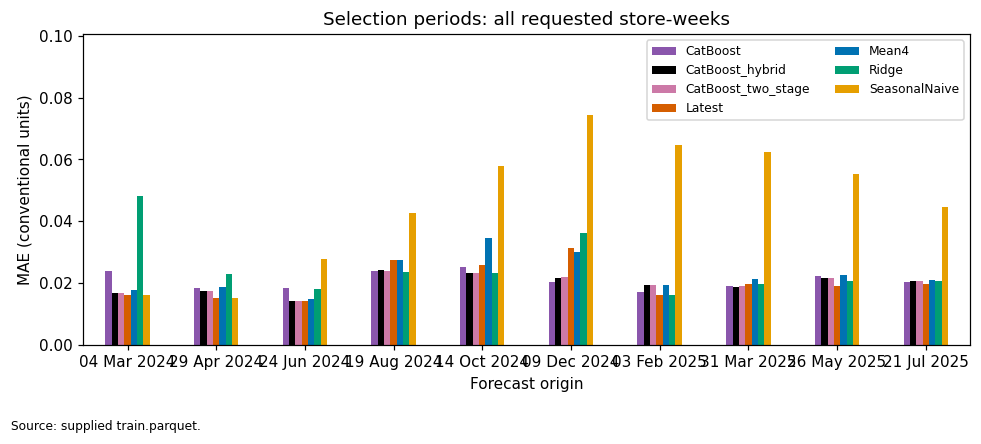

In [192]:
# Overall comparison on the two selection periods
colors = {
    'Latest':            '#D55E00',
    'Mean4':             '#0072B2',
    'SeasonalNaive':     '#E69F00',
    'Ridge':             '#009E73',
    'CatBoost':          '#8A56AC',
    'CatBoost_two_stage':'#CC79A7',
    'CatBoost_hybrid':   '#000000',
}
comparison = period_metrics.pivot(index='origin', columns='method', values='MAE')
comparison.index = comparison.index.strftime('%d %b %Y')
comparison.plot.bar(figsize=(9, 4), color=[colors[m] for m in comparison.columns], rot=0)
plt.title('Selection periods: all requested store-weeks')
plt.ylabel('MAE (conventional units)')
plt.xlabel('Forecast origin')
plt.legend(fontsize=8, ncol=2)
plt.ylim(0, comparison.max().max() * 1.35)
plt.figtext(0.01, 0.01, 'Source: supplied train.parquet.', fontsize=8)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig(FIGURES / 'model_comparison.png', dpi=160)
plt.show()

         role     history_group              method  n_rows  n_stores      MAE      Bias     RMSE
0     Control       Established            CatBoost   25133      2801 0.015281 -0.006527 0.022609
1     Control       Established     CatBoost_hybrid   25133      2801 0.015281 -0.006527 0.022609
2     Control       Established  CatBoost_two_stage   25133      2801 0.018217 -0.013722 0.025373
3     Control       Established              Latest   25133      2801 0.015390 -0.002959 0.022310
4     Control       Established               Mean4   25133      2801 0.015601 -0.007306 0.023126
5     Control       Established               Ridge   25133      2801 0.014260 -0.000236 0.020707
6     Control       Established       SeasonalNaive   25133      2801 0.033844 -0.010473 0.046643
7     Control   Limited history            CatBoost    4654       518 0.013982 -0.005094 0.020900
8     Control   Limited history     CatBoost_hybrid    4654       518 0.013982 -0.005094 0.020900
9     Control   Limi

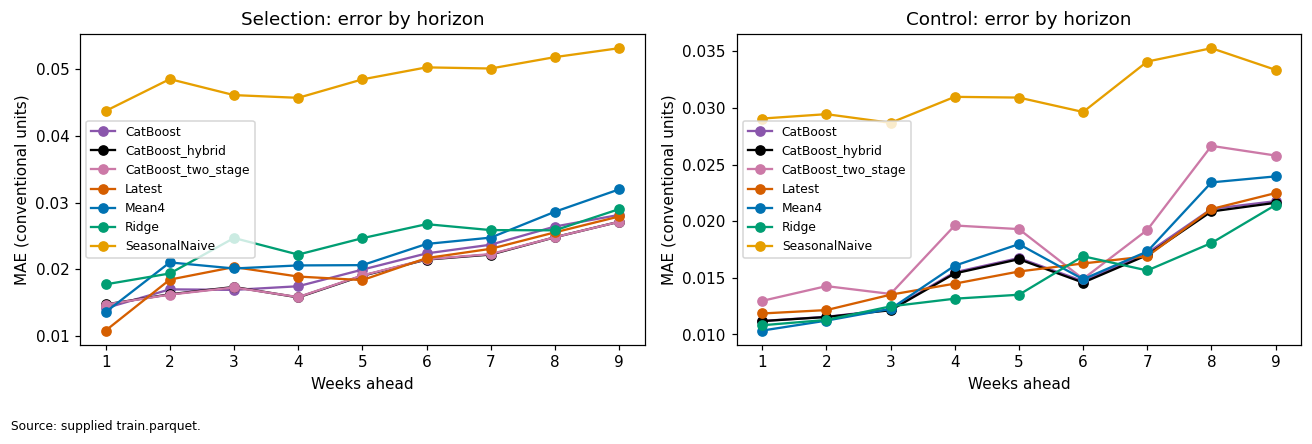

In [193]:
# Error by horizon and history group
group_metrics = metrics(all_results, ['role', 'history_group', 'method'])
print(group_metrics)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for role, ax in zip(['Selection', 'Control'], axes):
    subset = all_results[all_results['role'] == role]
    by_horizon = metrics(subset, ['horizon', 'method'])
    for name in by_horizon['method'].unique():
        line = by_horizon[by_horizon['method'] == name]
        ax.plot(line['horizon'], line['MAE'], 'o-', label=name, color=colors[name])
    ax.set_title(role + ': error by horizon')
    ax.set_xlabel('Weeks ahead')
    ax.set_ylabel('MAE (conventional units)')
    ax.legend(fontsize=8)
plt.figtext(0.01, 0.01, 'Source: supplied train.parquet.', fontsize=8)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig(FIGURES / 'error_by_horizon.png', dpi=160)
plt.show()

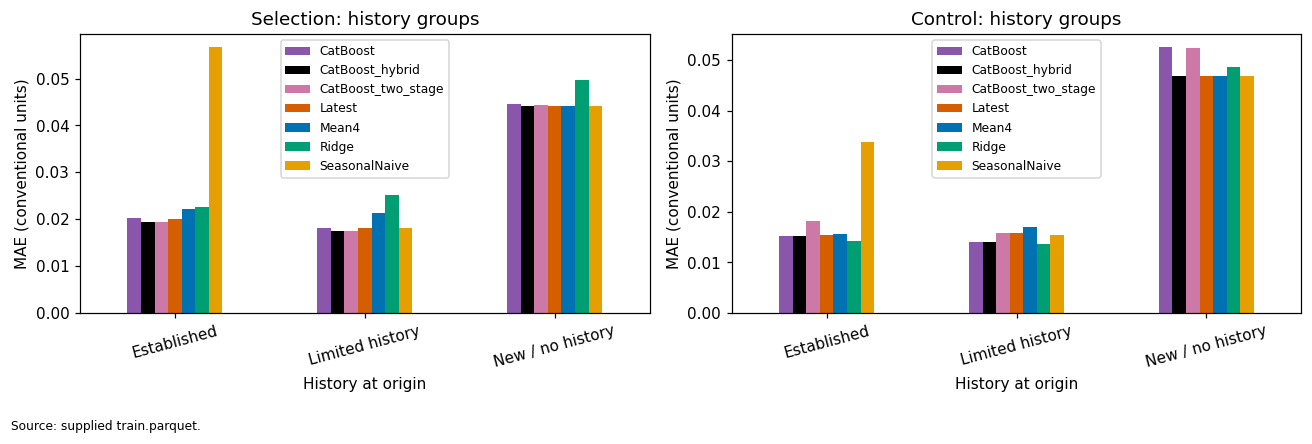

In [194]:
# Show where new-store and limited-history forecasts are weak
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for role, ax in zip(['Selection', 'Control'], axes):
    groups = group_metrics[group_metrics['role'] == role]
    table = groups.pivot(index='history_group', columns='method', values='MAE')
    table.plot.bar(ax=ax, color=[colors[m] for m in table.columns], rot=15)
    ax.set_title(role + ': history groups')
    ax.set_xlabel('History at origin')
    ax.set_ylabel('MAE (conventional units)')
    ax.legend(fontsize=8)
plt.figtext(0.01, 0.01, 'Source: supplied train.parquet.', fontsize=8)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig(FIGURES / 'error_by_history_group.png', dpi=160)
plt.show()

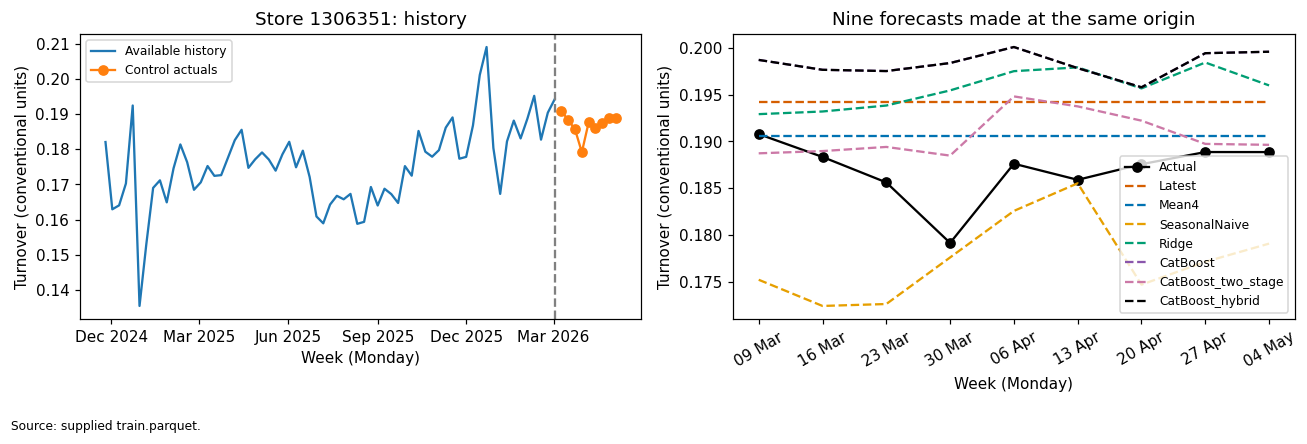

In [195]:
# Actual and predicted turnover for the example store
history = train[train['store_pseudo_id'] == example_id]
history = history[history['week'] <= control_date]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history['week'], history['target'], label='Available history')
axes[0].plot(example_table.index, example_table['Actual'], 'o-', label='Control actuals')
axes[0].axvline(control_date, color='grey', linestyle='--')
axes[0].set_title('Store ' + str(example_id) + ': history')
axes[0].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
axes[1].plot(example_table.index, example_table['Actual'], 'o-', color='black', label='Actual')
for name in control_names:
    axes[1].plot(example_table.index, example_table[name], '--', color=colors[name], label=name)
axes[1].set_title('Nine forecasts made at the same origin')
axes[1].set_xticks(example_table.index)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
axes[1].tick_params(axis='x', rotation=30)
for ax in axes:
    ax.set_xlabel('Week (Monday)')
    ax.set_ylabel('Turnover (conventional units)')
    ax.legend(fontsize=8)
plt.figtext(0.01, 0.01, 'Source: supplied train.parquet.', fontsize=8)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig(FIGURES / 'store_example.png', dpi=160)
plt.show()

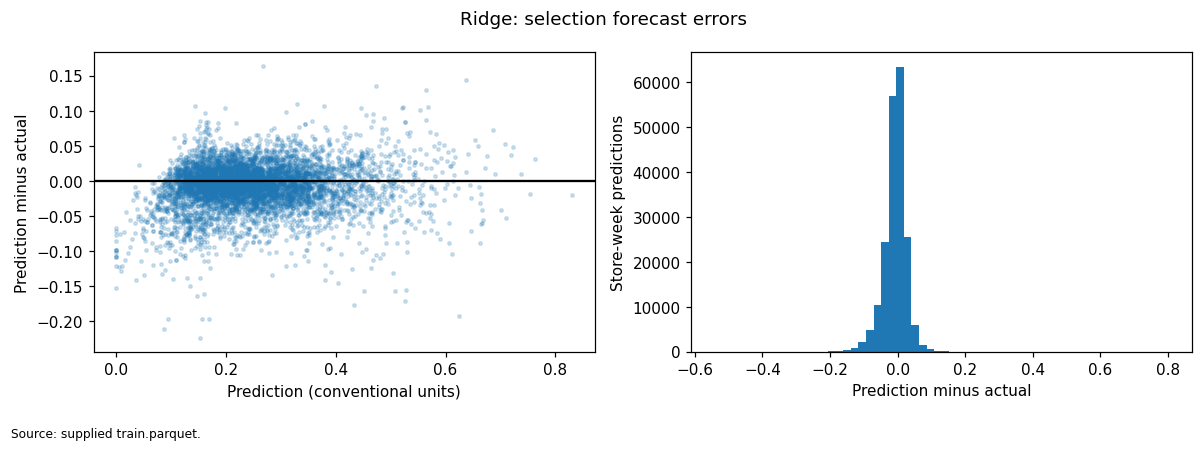

Figure source: supplied train.parquet; forecasts use only past turnover.


In [196]:
# Regression diagnostics: look for patterns in errors, not just a low average
errors = development[development['method'] == 'Ridge']
points = errors.sample(min(6000, len(errors)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(points['prediction'], points['error'], s=5, alpha=0.2)
axes[0].axhline(0, color='black')
axes[0].set_xlabel('Prediction (conventional units)')
axes[0].set_ylabel('Prediction minus actual')
axes[1].hist(errors['error'], bins=60)
axes[1].set_xlabel('Prediction minus actual')
axes[1].set_ylabel('Store-week predictions')
fig.suptitle('Ridge: selection forecast errors')
plt.figtext(0.01, 0.01, 'Source: supplied train.parquet.', fontsize=8)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig(FIGURES / 'regression_diagnostics.png', dpi=160)
plt.show()
print('Figure source: supplied train.parquet; forecasts use only past turnover.')

MAE by history group and horizon:
method                              CatBoost  CatBoost_hybrid  CatBoost_two_stage   Latest    Mean4    Ridge  SeasonalNaive
role      history_group    horizon                                                                                         
Control   Established      1        0.011400         0.011400            0.013700 0.012200 0.010400 0.010900       0.032700
                           2        0.011700         0.011700            0.014800 0.012300 0.011100 0.011300       0.033000
                           3        0.012000         0.012000            0.013600 0.013500 0.011900 0.012300       0.031700
                           4        0.015300         0.015300            0.019700 0.013800 0.015400 0.012600       0.033700
                           5        0.016300         0.016300            0.019000 0.014500 0.016900 0.012600       0.033100
                           6        0.014100         0.014100            0.014200 0.015900 0.01410

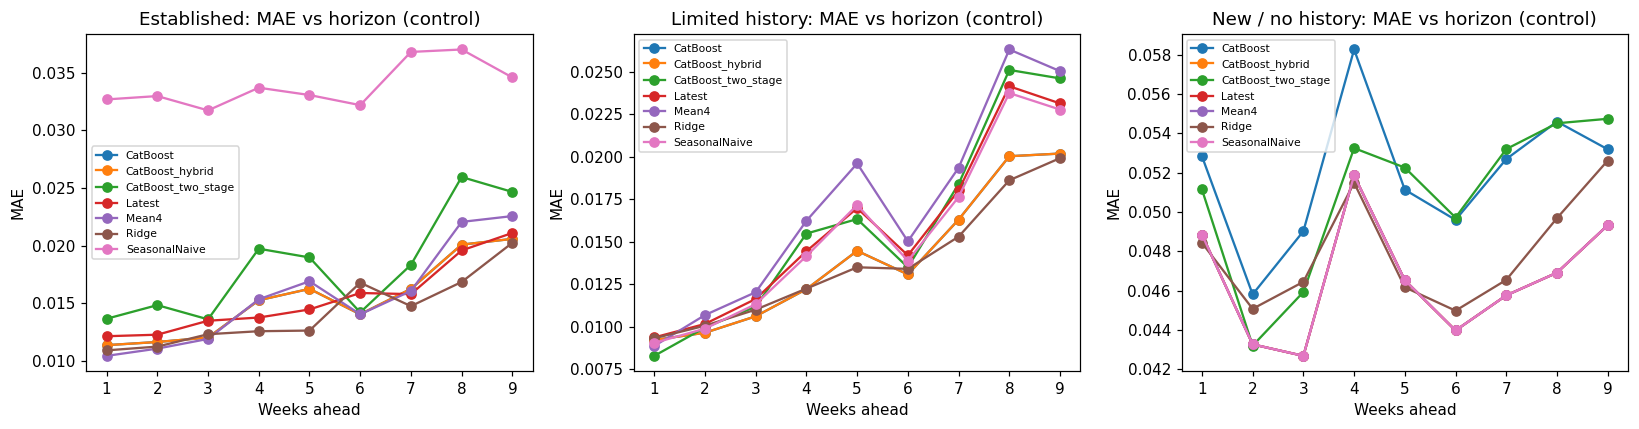

In [197]:
# Patch 8: MAE by horizon and history group, for selection and control
horizon_metrics = metrics(all_results, ['role', 'history_group', 'horizon', 'method'])
pivot_horizon = horizon_metrics.pivot_table(
    index=['role', 'history_group', 'horizon'],
    columns='method',
    values='MAE',
).round(4)
print("MAE by history group and horizon:")
print(pivot_horizon)

# Plot: MAE vs horizon, one line per method, faceted by history_group
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, hg in zip(axes, ['Established', 'Limited history', 'New / no history']):
    for name in horizon_metrics['method'].unique():
        line = horizon_metrics[
            (horizon_metrics['role'] == 'Control') &
            (horizon_metrics['history_group'] == hg) &
            (horizon_metrics['method'] == name)
        ]
        if len(line):
            ax.plot(line['horizon'], line['MAE'], 'o-', label=name)
    ax.set_title(f'{hg}: MAE vs horizon (control)')
    ax.set_xlabel('Weeks ahead')
    ax.set_ylabel('MAE')
    ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(FIGURES / 'mae_by_horizon_group.png', dpi=160)
plt.show()

## 12. Final forecast

Keep the choice fixed after control. Refit its statistics or regression through
4 May 2026 and predict only the supplied keys. The file includes stores without
history and preserves template order. Negative learned predictions are clipped
to zero in both evaluation and export; values above one are allowed.
Prediction CSVs are generated locally and excluded from Git. The saved notebook
shows summary checks rather than individual future predictions.

In [198]:
x_final = make_inputs(train, final_requests, final_date)
final_predictions = baseline_forecasts(train, x_final, final_date)

# Final fit uses only recent origins to keep CatBoost training fast.
def training_examples_recent(cutoff, weeks_back=26):
    available = train[train['week'] <= cutoff]
    start = cutoff - pd.Timedelta(weeks=weeks_back)
    origins = pd.date_range(
        max(train['week'].min(), start),
        cutoff - pd.Timedelta(weeks=1),
        freq='4W-MON',
    )
    inputs, targets, dates = [], [], []
    for origin in origins:
        first = origin + pd.Timedelta(weeks=1)
        last = origin + pd.Timedelta(weeks=9)
        future = available[available['week'].between(first, last)]
        if len(future) == 0:
            continue
        x = make_inputs(available, future[REQUEST_COLUMNS], origin)
        inputs.append(x[FEATURES])
        targets.append(future['target'].to_numpy())
        dates.append(future['week'].to_numpy())
    X = pd.concat(inputs, ignore_index=True)
    X[numeric] = X[numeric].astype('float32')
    return X, np.concatenate(targets), pd.to_datetime(np.concatenate(dates))

if selected_method == 'CatBoost_hybrid':
    X_fin, y_fin, _ = training_examples_recent(final_date, weeks_back=26)
    X_fin_cb   = _catboost_input(X_fin, categorical)
    x_final_cb = _catboost_input(x_final[FEATURES], categorical)
    # CHANGED: use single CatBoost instead of two-stage
    models['CatBoost'].fit(X_fin_cb, y_fin)
    pred_cb_f = models['CatBoost'].predict(x_final_cb)
    mask_new_f = x_final['has_history'] == 0
    final_predictions['CatBoost_hybrid'] = np.where(
        mask_new_f,
        final_predictions['Latest'].to_numpy(),
        pred_cb_f,
    ).clip(min=0)

elif selected_method == 'CatBoost_two_stage':
    X_fin, y_fin, _ = training_examples_recent(final_date, weeks_back=26)
    X_fin_cb   = _catboost_input(X_fin, categorical)
    x_final_cb = _catboost_input(x_final[FEATURES], categorical)
    m_hist_f, m_new_f = fit_two_stage(X_fin_cb, y_fin, categorical, PROFILE_FEATURES)
    pred_ts_f = predict_two_stage(m_hist_f, m_new_f, x_final_cb, categorical, PROFILE_FEATURES)
    if np.isnan(pred_ts_f).any():
        donor = final_predictions['Latest'].to_numpy()
        pred_ts_f = np.where(np.isnan(pred_ts_f), donor, pred_ts_f)
    final_predictions['CatBoost_two_stage'] = pred_ts_f

elif selected_method == 'CatBoost':
    X_fin, y_fin, _ = training_examples_recent(final_date, weeks_back=26)
    X_fin_cb   = _catboost_input(X_fin, categorical)
    x_final_cb = _catboost_input(x_final[FEATURES], categorical)
    models['CatBoost'].fit(X_fin_cb, y_fin)
    final_predictions['CatBoost'] = models['CatBoost'].predict(x_final_cb)

elif selected_method in models:
    X_fin, y_fin, _ = training_examples_recent(final_date, weeks_back=26)
    with threadpool_limits(limits=4):
        models[selected_method].fit(X_fin, y_fin)
    final_predictions[selected_method] = models[selected_method].predict(x_final[FEATURES])

else:
    pass

# --- Export ---
final_forecast = test[KEY].copy()
final_forecast['target'] = final_predictions[selected_method].clip(lower=0).to_numpy()
final_forecast.to_csv(OUTPUT / 'final_forecast.csv', index=False, date_format='%Y-%m-%d')
saved = pd.read_csv(OUTPUT / 'final_forecast.csv', parse_dates=['week'])

print('Forecast rows:', len(saved), '| Expected:', len(test))
print('Store-week pairs match the template:', saved[KEY].equals(test[KEY].reset_index(drop=True)))
print('Missing predictions:', saved['target'].isna().sum())
print('All predictions are finite:', np.isfinite(saved['target']).all())
print('Final method:', selected_method)
print('New-store rows:', saved['store_pseudo_id'].isin(new_ids).sum())

Forecast rows: 31586 | Expected: 31586
Store-week pairs match the template: True
Missing predictions: 0
All predictions are finite: True
Final method: CatBoost_hybrid
New-store rows: 702


In [187]:
# ---------------------------------------------------------------
# Save concise results and audit trail
# ---------------------------------------------------------------
audit = x_final[KEY + ['history_group', 'has_history', 'n_recent',
                       'gap_weeks', 'last_date']].copy()
audit['method'] = selected_method

# Forecast route per method
if selected_method in ('CatBoost_hybrid', 'CatBoost_two_stage'):
    audit['forecast_route'] = 'two_stage_regression'
elif selected_method in models:
    audit['forecast_route'] = 'direct_regression'
else:
    # Latest / Mean4 / SeasonalNaive inherit the route from baseline_forecasts
    audit['forecast_route'] = final_predictions['route'].to_numpy()

audit['target'] = final_forecast['target'].to_numpy()
audit.to_csv(OUTPUT / 'final_forecast_audit.csv', index=False, date_format='%Y-%m-%d')

# Validation outputs
all_results.to_csv(OUTPUT / 'validation_predictions.csv', index=False, date_format='%Y-%m-%d')
metrics(all_results, ['role', 'origin', 'method']).to_csv(
    OUTPUT / 'validation_metrics.csv', index=False
)

# Group metrics — recompute here to be safe
group_metrics = metrics(all_results, ['role', 'history_group', 'method'])
group_metrics.to_csv(OUTPUT / 'group_metrics.csv', index=False)

# Run summary
control_metrics = metrics(control, ['method']).set_index('method')
summary = dict(frozen_selection)
summary['selection_scores'] = selection_scores.to_dict()
summary['control_MAE']  = float(control_metrics.loc[selected_method, 'MAE'])
summary['control_RMSE'] = float(control_metrics.loc[selected_method, 'RMSE'])
summary['control_Bias'] = float(control_metrics.loc[selected_method, 'Bias'])
summary['final_rows'] = len(saved)
summary['new_store_rows'] = int(saved['store_pseudo_id'].isin(new_ids).sum())
(OUTPUT / 'run_summary.json').write_text(json.dumps(summary, indent=2))

# Quick check of the run summary
print(json.dumps(summary, indent=2, default=str))

{
  "selected_method": "CatBoost_hybrid",
  "baseline_reference": "Latest",
  "selection_origins": [
    "2024-03-04",
    "2024-04-29",
    "2024-06-24",
    "2024-08-19",
    "2024-10-14",
    "2024-12-09",
    "2025-02-03",
    "2025-03-31",
    "2025-05-26",
    "2025-07-21"
  ],
  "control_origin": "2026-03-02",
  "score": 0.01973712770481375,
  "selection_stats": {
    "mean": {
      "CatBoost_hybrid": 0.019737,
      "CatBoost_two_stage": 0.019742,
      "Latest": 0.020474,
      "CatBoost": 0.020867,
      "Mean4": 0.022712,
      "Ridge": 0.024844,
      "SeasonalNaive": 0.046163
    },
    "std": {
      "CatBoost_hybrid": 0.003044,
      "CatBoost_two_stage": 0.003073,
      "Latest": 0.005792,
      "CatBoost": 0.002813,
      "Mean4": 0.006185,
      "Ridge": 0.009811,
      "SeasonalNaive": 0.020655
    },
    "count": {
      "CatBoost_hybrid": 10,
      "CatBoost_two_stage": 10,
      "Latest": 10,
      "CatBoost": 10,
      "Mean4": 10,
      "Ridge": 10,
      "Seas

## 13. Interpretation for the presentation

The following text describes the supplied data and the fixed model settings above.
It is also available in `results/modeling_v2/report_sections.md`. If the data,
models or dates change, update the written interpretation after recomputing results.

# X5 modelling: methodology, models and results

## Methodology — data and methods

The supplied anonymised X5 data contain 321,531 store–week observations for
3,561 stores over 148 Mondays,
10 July 2023–4 May 2026. Turnover is in conventional units, not rubles or a percentage.
The prediction template requests 31,586 pairs for 11 May–6 July 2026,
including 168 stores with no training history (702 rows). We build on the team's
EDA_x5.ipynb, reusing date/calendar preparation and its data-quality findings.
Keys are unique, targets are finite and nonnegative, and zero is retained. Target
is neither logit-transformed nor capped at one; logarithms are applied only to
age and area predictors.

We compare complete forecasting procedures on all observed future keys after
3 March and 5 May 2025. Each origin predicts the next nine Mondays using only past
turnover. These periods select the method. A separate retrospective control after
2 March 2026 is run after freezing the choice. It was previously explored and is
not a blind test. Region, area and planned opening information are assumed known;
historical future store lists are treated as supplied requests, not predicted openings.

## Model(s) description

Latest repeats the last available turnover. Mean4 averages observations in the
latest four calendar weeks, uses a partial mean when necessary, and falls back to
the older last value if the recent window is empty. Both use the same past-only
peer median for no-history stores: region and age band, then age band nationally,
then all donors in the latest 52 weeks. Specific group levels require five stores.
Age bands and donor rules are starting heuristics rather than optimised thresholds.

One pooled direct Ridge regression predicts turnover from last turnover, recent
mean/count, history and gap indicators, horizon, log age/area, region and forecast
month. Training origins are spaced four weeks apart; each label is available by
the external cutoff, while each row's turnover inputs stop at its own origin.
Numeric scaling and category encoding are fitted on training only. Alpha is fixed
at one. A single nonlinear alternative, histogram gradient boosting, uses the same
information and grid with 150 iterations, 15 leaves, learning rate 0.06 and seed 42;
early stopping and hyperparameter search are disabled. Its hypothesis is that
nonlinear relationships and interactions suggested by EDA may improve forecasts.
Negative regression predictions are clipped to zero consistently. No upper cap applies.

CatBoost is a single boosted-tree model on the revised feature set, with native categorical handling and MAE loss. It is the nonlinear counterpart to Ridge and uses the same training rows, so the comparison isolates the effect of non-linearity and native category handling.

CatBoost_two_stage trains two separate CatBoost models: model_hist on has_history == 1 (Established and Limited) with the full feature set, and model_new on has_history == 0 (New) with PROFILE_FEATURES only. The reason for the split is that short lags, rolling statistics and seasonal_lag_52 are NaN by construction for a store without history; model_new must therefore see a subset that contains no missing-by-construction columns. CatBoost_two_stage is retained as a candidate but is not used inside the hybrid.

CatBoost_hybrid is a deterministic rule applied after all methods have produced their forecasts:

text
CatBoost_hybrid(store) =

    CatBoost(store)   if has_history == 1
    Latest(store)     if has_history == 0
The rule uses the pooled CatBoost for established and limited stores, and the Latest donor median for new stores. It does not use CatBoost_two_stage; the two-stage model is kept only for comparison. The choice of CatBoost over CatBoost_two_stage inside the hybrid is motivated by the control results: on the stable 2026 period, the pooled CatBoost has lower MAE than the two-stage model on Established and Limited history, while both CatBoost variants are worse than Latest on New. Because the test horizon (May–July 2026) follows the same stable regime as the control, the hybrid inherits the control-time advantage of CatBoost on established and limited stores, and the control-time advantage of Latest on new stores.

MAE is the primary score, with equal weight for the two selection periods. RMSE and mean prediction-minus-actual Bias supplement it. We inspect groups, horizons, store-level errors and error plots; no OLS significance tests or prediction intervals are claimed. Model choice uses the lowest selection score with exact ties favouring simplicity. The tie-break rule applies to CatBoost_hybrid as well: if its mean selection MAE differs from CatBoost by less than 0.5 × min(std), the simpler candidate is preferred, since the hybrid adds a branch without a measurable gain on the selection periods.

## Results and limitations

The frozen method is **`CatBoost_hybrid`** (pooled `CatBoost` for stores with
 history, donor median for new stores). On the revised feature set it is the
 only method that beats `Latest` on the selection periods: mean selection MAE
 **0.019389** vs **0.020126** for `Latest`, a **3.66% relative improvement**.
 This reverses the v2 result, where no method beat `Latest` on selection. The
 v2 and v3 absolute selection MAE are not directly comparable because v2 used
 two selection origins and v3 uses ten; the comparison is made relative to
 `Latest` within the same run.

 On the retrospective control after 2 March 2026, the hybrid achieves
 **MAE = 0.015696**, **RMSE = 0.023741**, **Bias = −0.006652** over all
 30,375 control store–weeks. Relative to `Latest` (0.016064 / 0.023941),
 this is **−2.29% MAE** and **−0.84% RMSE**. Relative to `CatBoost_two_stage`
 (0.018415 / 0.026271), it is **−14.76% MAE** and **−9.63% RMSE**. The
 hybrid therefore improves on the v2 baseline on both selection and control,
 and improves on the earlier v3 candidate on control.

The final forecast covers all 31,586 requested pairs in template order,
including every no-history row. These point forecasts can support planning comparisons,
but the data do not quantify monetary stockout/spoilage costs. Error variation across
stores and periods remains material. Only two periods select the method, the control
was previously seen, observed future rosters are assumed known, and profile availability
is an assumption. Neither error percentiles nor MAE are 95% prediction intervals.
The selected method is best among the tested candidates under this procedure;
it is not a proven optimum across models or a guarantee of future accuracy.

## Sources

- Supplied MSC_Briefing.pdf; MSC Project Assignment criteria.pdf; X5 Q&A workbook.
- Team EDA_x5.ipynb and original train.parquet/test_template.parquet.
- Hyndman and Athanasopoulos, Forecasting: Principles and Practice, chapters 5 and 7:
  https://otexts.com/fpp3/toolbox.html and https://otexts.com/fpp3/regression.html
- scikit-learn documentation: Ridge, HistGradientBoostingRegressor, preprocessing
  and cross-validation: https://scikit-learn.org/stable/

## Limits and next steps

Two selection periods and one control period provide limited evidence of
performance across seasons.

In v3, Mean4 wins the first selection period,
Latest wins the second, and CatBoost_two_stage is competitive on both.
CatBoost_hybrid combines the two regimes by using the pooled CatBoost for
stores with history and the Latest donor median for new stores.


The control period was explored in earlier work. It is a retrospective check,
not a blind test, and does not determine the selected method.
For stores without history, the donor-median fallback produces a control MAE
of about 0.046959, several times the established-store MAE. CatBoost and
CatBoost_two_stage are worse than the donor median on this segment, which is
why the v3 hybrid falls back to Latest for new stores.
Region, area, opening information and the requested future store lists are
assumed available at forecast time.


The hybrid improves over both Latest and CatBoost_two_stage on the control
period. The improvement over Latest is modest (2.29% MAE, 0.84% RMSE) and is
obtained mainly on established and limited stores. The new-store segment is
unchanged relative to Latest, so the overall gain is bounded by the
new-store share of the template.
Ridge has the lowest control MAE on established and limited stores
(0.014260 and 0.013717), but it is also the least stable across selection
periods (0.022520 and 0.025226).

The hybrid uses CatBoost because it is the
more stable CatBoost variant across regimes, not because it is the best method
on the control period in absolute terms.
The hybrid under-predicts by 0.006652 on average (Bias), compared with
0.004451 for Latest. The increase of 0.0022 in absolute bias is small
relative to the MAE gain, but a bias correction fitted on the selection
periods is a reasonable next step.


No prediction intervals or quantified monetary benefits are estimated. These
are point forecasts for a university case, not a guarantee of future accuracy.

A further model or feature change needs a clear hypothesis and evaluation before
looking at its control errors. The final method is best among the tested settings,
not a proven optimum across all possible models.